# F1: What is a starting grid slot worth?

A clean dataset of Formula 1 history (1950–2025) built from two independent sources —
the **Jolpica F1 API** (circuits, every race result) and **Wikipedia** (circuit type,
length, direction, status) — joined and analyzed to answer one question:

> **How much does the slot you start from decide the race — and has that changed over 75 years?**

This notebook runs the whole pipeline end to end:

1. **Clean** the raw API results (`clean_data.py`)
2. **Join** the API and Wikipedia circuit tables (`join_circuits.py`)
3. **Analyze** grid value, pole conversion, all-time winners
4. **Use the join**: does the answer differ on street circuits?
5. **Map** every circuit F1 has ever raced on

## 1. Run the pipeline

`clean_data.py` drops the Indy 500 (championship rounds 1950–60 that F1 drivers didn't
actually race), the not-yet-raced 2026 season, and pit-lane starts (no grid slot to
analyze). `join_circuits.py` matches all 78 circuits 1:1 between the two sources —
61 by name normalization, 17 by a hand-written mapping.

In [1]:
%run clean_data.py

raw rows:            26313
- Indy 500:          405
- season 2026:       440
- pit-lane (grid=0): 267
kept rows:           25201  (1138 races, seasons 1950-2025)
written to:          data/clean_results.csv


In [2]:
%run join_circuits.py

joined 78 circuits (17 matched by hand)
written to: data/circuits_joined.csv


In [3]:
import io
import pandas as pd
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import Image, display

RED, GREY, BLUE = "#e10600", "#444444", "#1e6fd9"

def new_axes(figsize=(9, 5)):
    fig = Figure(figsize=figsize)
    FigureCanvasAgg(fig)
    return fig, fig.add_subplot()

def show(fig):
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    display(Image(buf.getvalue()))

results = pd.read_csv("data/clean_results.csv")
circuits = pd.read_csv("data/circuits_joined.csv")

print(f"{len(results):,} results, {results['season'].nunique()} seasons, {len(circuits)} circuits")
results.head(3)

25,201 results, 76 seasons, 78 circuits


,season,round,race_name,race_date,circuit_id,driver_id,driver_code,driver_name,driver_nationality,driver_dob,...,position_order,points,laps,status,race_time_ms,fastest_lap_rank,fastest_lap_time,field_size,win,podium
0,1950,1,British Grand Prix,1950-05-13,silverstone,farina,NaN,Nino Farina,Italian,1906-10-30,...,NaN,9.0,70,Finished,8003600.0,NaN,NaN,23,1,1
1,1950,1,British Grand Prix,1950-05-13,silverstone,fagioli,NaN,Luigi Fagioli,Italian,1898-06-09,...,NaN,6.0,70,Finished,8006200.0,NaN,NaN,23,0,1
2,1950,1,British Grand Prix,1950-05-13,silverstone,reg_parnell,NaN,Reg Parnell,British,1911-07-02,...,NaN,4.0,70,Finished,8055600.0,NaN,NaN,23,0,1


## 2. The value of a grid slot

Across every race since 1950: how often does each starting slot win or reach the podium,
and where does it finish on average?

In [4]:
grid = (results.groupby("grid")
        .agg(starts=("win", "size"), win_pct=("win", "mean"),
             podium_pct=("podium", "mean"), avg_finish=("position", "mean"))
        .assign(win_pct=lambda d: 100 * d.win_pct,
                podium_pct=lambda d: 100 * d.podium_pct)
        .round(2))
grid.head(10)

,starts,win_pct,podium_pct,avg_finish
grid,,,,
1,1149,43.08,64.14,5.53
2,1137,23.75,56.46,6.46
3,1142,12.26,46.50,7.42
4,1143,6.04,34.47,8.01
5,1144,4.20,24.91,9.00
6,1136,3.43,18.40,9.55
7,1145,1.83,12.75,10.00
8,1139,1.49,9.75,10.60
9,1143,0.44,8.05,10.82


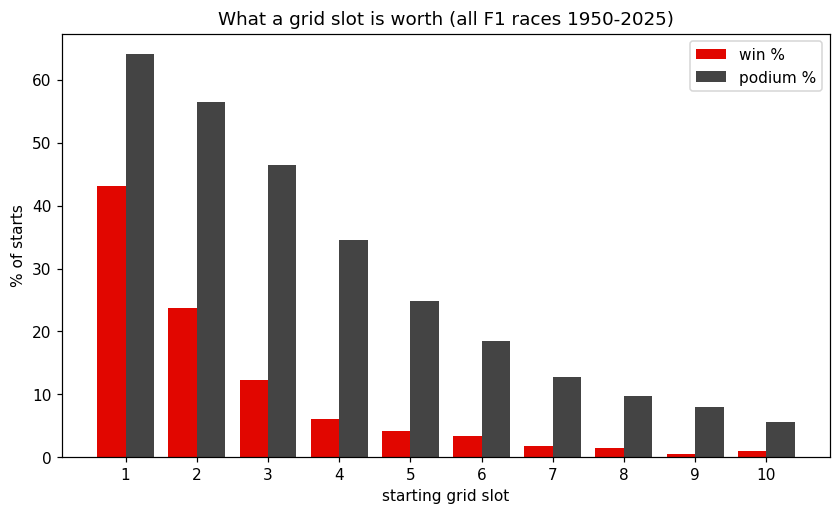

In [5]:
top10 = grid.head(10)
fig, ax = new_axes()
ax.bar(top10.index - 0.2, top10.win_pct, width=0.4, color=RED, label="win %")
ax.bar(top10.index + 0.2, top10.podium_pct, width=0.4, color=GREY, label="podium %")
ax.set_xticks(top10.index)
ax.set_xlabel("starting grid slot")
ax.set_ylabel("% of starts")
ax.set_title("What a grid slot is worth (all F1 races 1950-2025)")
ax.legend()
show(fig)

Pole wins **43%** of all races; P10 about **1%**. Podium chances fall by
roughly a third with every row you move back. The starting slot is not everything —
but it is close to half of everything.

## 3. Has pole become more decisive?

Share of races won from pole position, per decade.

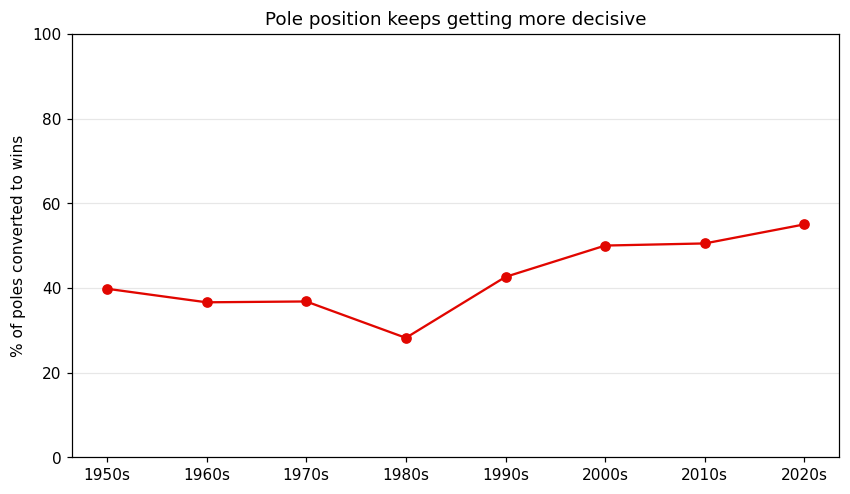

,sum,size,conversion_pct
decade,,,
1950,33,83,39.8
1960,37,101,36.6
1970,53,144,36.8
1980,44,156,28.2
1990,69,162,42.6
2000,87,174,50.0
2010,100,198,50.5
2020,72,131,55.0


In [6]:
poles = results[results.grid == 1]
by_decade = (poles.assign(decade=poles.season // 10 * 10)
             .groupby("decade")["win"].agg(["sum", "size"]))
by_decade["conversion_pct"] = (100 * by_decade["sum"] / by_decade["size"]).round(1)

fig, ax = new_axes()
ax.plot(by_decade.index, by_decade.conversion_pct, marker="o", color=RED)
ax.set_xticks(by_decade.index)
ax.set_xticklabels([f"{d}s" for d in by_decade.index])
ax.set_ylabel("% of poles converted to wins")
ax.set_ylim(0, 100)
ax.set_title("Pole position keeps getting more decisive")
ax.grid(axis="y", alpha=0.3)
show(fig)
by_decade

Conversion dipped to **28%** in the turbo-and-attrition 1980s, then climbed
steadily to **55%** in the 2020s: modern cars rarely break down, and modern aerodynamics
make overtaking the leader hard — track position is worth more than ever.

## 4. All-time winners

In [7]:
wins = results[results.win == 1]
drivers = wins.driver_name.value_counts().head(10).rename("wins").reset_index()
constructors = wins.constructor_name.value_counts().head(10).rename("wins").reset_index()
pd.concat([drivers, constructors], axis=1)

,driver_name,wins,constructor_name,wins
0,Lewis Hamilton,105,Ferrari,249
1,Michael Schumacher,91,McLaren,199
2,Max Verstappen,71,Mercedes,131
3,Sebastian Vettel,53,Red Bull,130
4,Alain Prost,51,Williams,114
5,Ayrton Senna,41,Team Lotus,45
6,Fernando Alonso,32,Renault,35
7,Nigel Mansell,31,Benetton,27
8,Jackie Stewart,27,Brabham,23
9,Jim Clark,25,Tyrrell,23


## 5. Street circuits vs the rest — the join pays off

Only the joined dataset can answer this: the Wikipedia side knows each circuit's **type**
(street / road / race circuit), the API side links circuits to 25,000 results. Is grid
position more decisive where the walls are close and overtaking is hard?

In [8]:
merged = results.merge(circuits[["circuit_id", "type", "status"]], on="circuit_id")

by_type = (merged[merged.grid == 1]
           .groupby("type")["win"]
           .agg(poles="size", wins_from_pole="sum", conversion_pct="mean"))
by_type["conversion_pct"] = (100 * by_type["conversion_pct"]).round(1)
by_type.sort_values("conversion_pct", ascending=False)

,poles,wins_from_pole,conversion_pct
type,,,
Street circuit,227,103,45.4
Race circuit,884,377,42.6
Road circuit,38,15,39.5


In [9]:
monaco = merged[merged.circuit_id == "monaco"]
mon_pct = 100 * monaco[monaco.grid == 1]["win"].mean()
rest_pct = 100 * merged[(merged.circuit_id != "monaco") & (merged.grid == 1)]["win"].mean()
print(f"Pole-to-win at Monaco:          {mon_pct:.0f}%")
print(f"Pole-to-win everywhere else:    {rest_pct:.0f}%")

Pole-to-win at Monaco:          46%
Pole-to-win everywhere else:    43%


## 6. Every circuit F1 has raced on

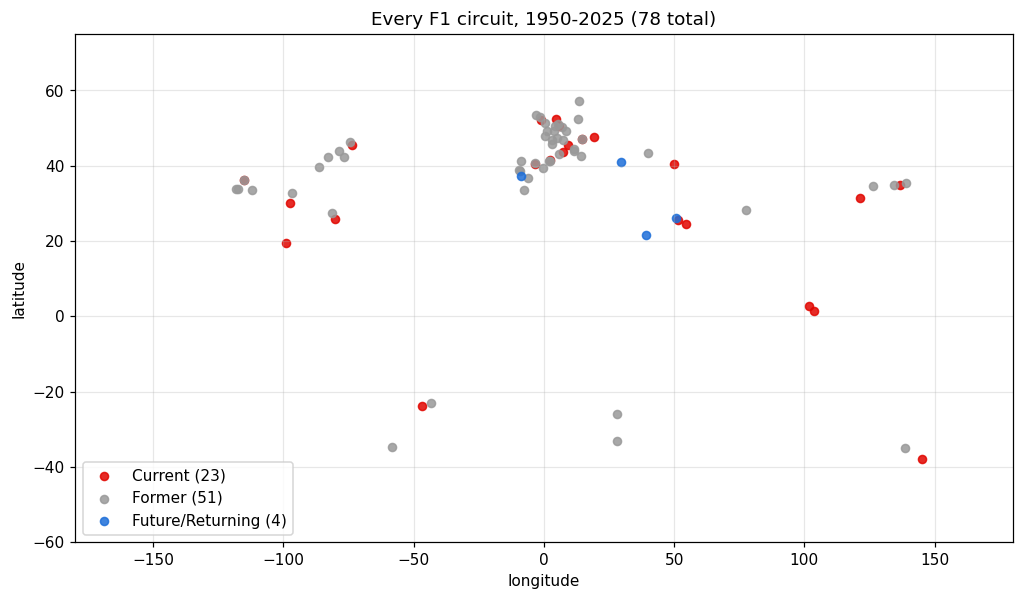

In [10]:
colors = {"Current": RED, "Former": "#999999", "Future/Returning": BLUE}
fig, ax = new_axes(figsize=(11, 6))
for status, c in colors.items():
    pts = circuits[circuits.status == status]
    ax.scatter(pts["long"], pts["lat"], s=28, color=c,
               label=f"{status} ({len(pts)})", alpha=0.85)
ax.set_xlim(-180, 180); ax.set_ylim(-60, 75)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
ax.set_title(f"Every F1 circuit, 1950-2025 ({len(circuits)} total)")
ax.legend(loc="lower left"); ax.grid(alpha=0.3)
show(fig)

## Conclusion

- The starting slot is close to destiny: **pole wins 43%** of all races, P10 almost none.
- Pole has grown **more** decisive over time — 55% conversion in the 2020s vs 28% in the 1980s.
- The two-source join earned its keep: circuit *type* (Wikipedia) × race results (API)
  shows how much track character shapes the value of qualifying.

**Data:** Jolpica F1 API (Ergast-compatible) + Wikipedia "List of Formula One circuits".
**Pipeline:** `collect_api.py` / `websrcaping.py` → `clean_data.py` → `join_circuits.py` → this notebook.